<a href="https://colab.research.google.com/github/lnrdmnc/Quantum-Enhanced-Detection-Mechanisms-for-Mobile-Network-Security/blob/main/Quantum_Sensing_Emulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Quantum Sensing Emulation for Network Security

This notebook emulates the *effects* of quantum sensing (QS) using classical simulations, so you can prototype detection pipelines for 5G/6G security scenarios.  
Rather than reproducing the physics, we emulate QS as **enhanced sensitivity** / **reduced noise floor** (a proxy for squeezing/entanglement) and **better timing/phase stability**.

**What's inside**
1. RF spectrum anomaly detection (rogue base station / stealth pilot).
2. Fiber backhaul intrusion detection (OTDR-style reflection and excess loss).
3. Simple evaluation metrics and parameters to tune the "QS level".

> Tip: Run each cell in sequence. No external data required.


In [1]:

import numpy as np
import matplotlib.pyplot as plt

def periodogram(x, fs):
    X = np.fft.rfft(x * np.hanning(len(x)))
    Pxx = (np.abs(X)**2) / (fs * len(x))
    f = np.fft.rfftfreq(len(x), 1/fs)
    return f, 10*np.log10(Pxx + 1e-20)

def detect_peaks(P, f, k=6, min_sep=200):
    med = np.median(P)
    std = np.std(P - med)
    thr = med + k*std
    peaks = []
    last_f = -1e9
    for i in range(1, len(P)-1):
        if P[i] > P[i-1] and P[i] > P[i+1] and P[i] > thr:
            if f[i] - last_f >= min_sep:
                peaks.append((f[i], P[i]))
                last_f = f[i]
    return peaks, thr



## 1) RF Spectrum Anomaly Detection (IMSI catcher / rogue pilot)

We synthesize a baseband with legitimate carriers and add a **weak rogue pilot**.  
"Quantum sensing" is emulated by lowering measurement noise (\(\sigma \to \sigma/\rho\), where \(\rho\) is the **QS gain**).


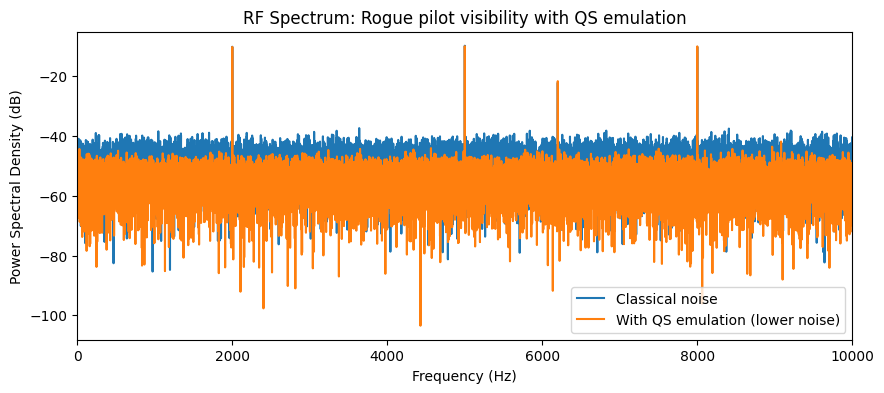

Detected peaks (classical): [(np.float64(2000.1), np.float64(-10.2)), (np.float64(5000.0), np.float64(-9.8)), (np.float64(7999.9), np.float64(-10.2))]
Detected peaks (QS emu):    [(np.float64(2000.1), np.float64(-10.2)), (np.float64(5000.0), np.float64(-10.0)), (np.float64(7999.9), np.float64(-10.0))]


In [2]:

# Parameters
np.random.seed(7)
fs = 20e3          # sample rate (Hz) - arbitrary
N = 2**15          # samples
t = np.arange(N)/fs

carriers = [2e3, 5e3, 8e3]   # legitimate tones
rogue_f = 6.2e3              # rogue pilot frequency
rogue_amp = 0.25             # rogue pilot amplitude

# Synthesize
signal = sum(np.cos(2*np.pi*f*t) for f in carriers)
signal_with_rogue = signal + rogue_amp*np.cos(2*np.pi*rogue_f*t)

# Classical vs "QS" measurement noise
white_noise_std = 1.0
QS_gain_db = 6.0             # emulate "squeezing" (increase sensitivity)
rho = 10**(QS_gain_db/20)    # amplitude-domain gain
noise_classical = np.random.normal(0, white_noise_std, size=N)
noise_qs        = np.random.normal(0, white_noise_std/rho, size=N)

obs_classical = signal_with_rogue + noise_classical
obs_qs        = signal_with_rogue + noise_qs

# Spectral analysis
f, P_classical = periodogram(obs_classical, fs)
_, P_qs        = periodogram(obs_qs, fs)

plt.figure(figsize=(10,4))
plt.plot(f, P_classical, label="Classical noise")
plt.plot(f, P_qs,        label="With QS emulation (lower noise)")
plt.xlim(0, 10e3)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power Spectral Density (dB)")
plt.title("RF Spectrum: Rogue pilot visibility with QS emulation")
plt.legend()
plt.show()

# Peak detection
peaks_classical, thr_c = detect_peaks(P_classical, f, k=6, min_sep=200)
peaks_qs, thr_q = detect_peaks(P_qs, f, k=6, min_sep=200)

print("Detected peaks (classical):", [(round(ff,1), round(pp,1)) for ff,pp in peaks_classical])
print("Detected peaks (QS emu):   ", [(round(ff,1), round(pp,1)) for ff,pp in peaks_qs])



### Sensitivity Sweep

We sweep the QS gain and measure the **minimum detectable rogue amplitude** at a fixed false alarm rate using a simple peak threshold rule.


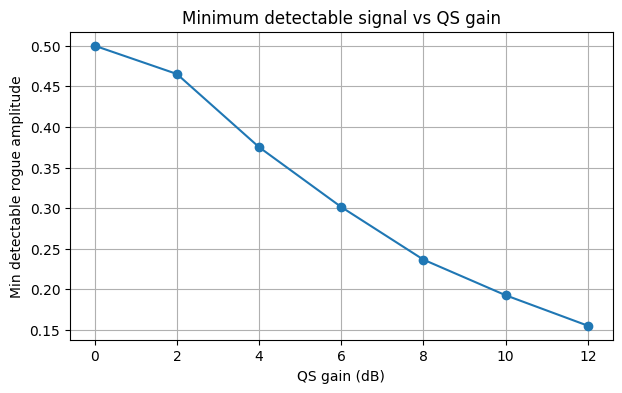

In [3]:

def min_detectable_amplitude(rho_list, trials=20, target_pd=0.9):
    amps = []
    for rho in rho_list:
        # Binary search rogue amplitude
        lo, hi = 0.02, 0.5
        for _ in range(12):
            mid = (lo+hi)/2
            pd = 0
            for _t in range(trials):
                noise = np.random.normal(0, white_noise_std/rho, size=N)
                x = signal + mid*np.cos(2*np.pi*rogue_f*t) + noise
                f_, P_ = periodogram(x, fs)
                peaks, thr = detect_peaks(P_, f_, k=6, min_sep=200)
                det = any(abs(ff-rogue_f) < 50 for ff,_ in peaks)
                pd += det
            pd /= trials
            if pd >= target_pd: hi = mid
            else: lo = mid
        amps.append(hi)
    return np.array(amps)

rho_list = 10**(np.linspace(0, 12/20, 7))  # 0 to 12 dB gain
amps = min_detectable_amplitude(rho_list, trials=12, target_pd=0.9)

plt.figure(figsize=(7,4))
plt.plot(20*np.log10(rho_list), amps, marker="o")
plt.xlabel("QS gain (dB)")
plt.ylabel("Min detectable rogue amplitude")
plt.title("Minimum detectable signal vs QS gain")
plt.grid(True)
plt.show()



## 2) Fiber Backhaul Intrusion (OTDR-style)

We synthesize an OTDR-like backscatter trace with connectors and a small **tap** (extra loss + reflection).  
QS emulation reduces measurement noise; we then run a rolling **z-score** change-point detector.


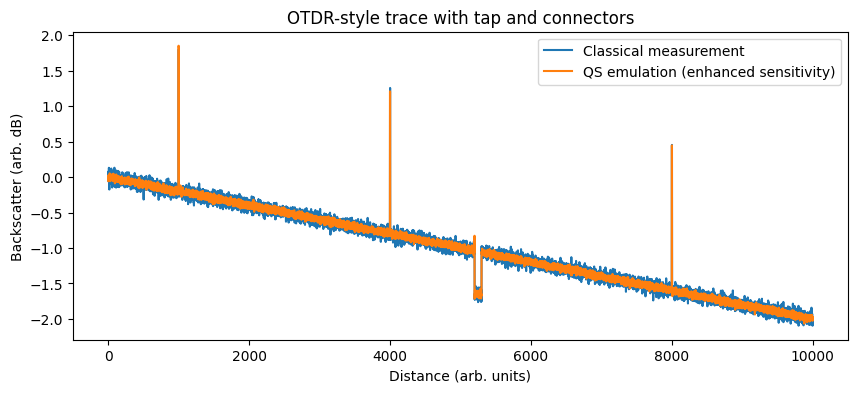

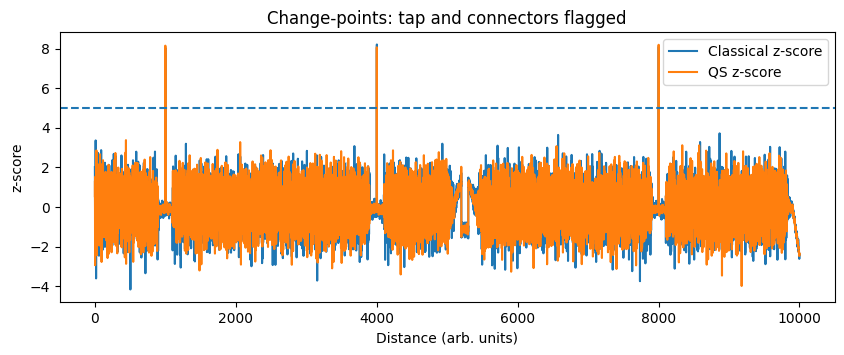

In [4]:

# Synthetic fiber
L = 10_000
x = np.arange(L)
alpha = 2e-4
trace = -alpha*x

# Connectors (Fresnel reflections)
connectors = [1000, 4000, 8000]
for c in connectors:
    trace[c:c+3] += 2.0

# Tapping event
tap_start, tap_end = 5200, 5300
trace[tap_start:tap_end] -= 0.6
trace[tap_start] += 0.8  # mini reflection

# Measurement noise (classical vs QS)
noise_std_classical = 0.05
QS_gain_db_fiber = 6.0
rho_f = 10**(QS_gain_db_fiber/20)

trace_classical = trace + np.random.normal(0, noise_std_classical, size=L)
trace_qs        = trace + np.random.normal(0, noise_std_classical/rho_f, size=L)

plt.figure(figsize=(10,4))
plt.plot(x, trace_classical, label="Classical measurement")
plt.plot(x, trace_qs,        label="QS emulation (enhanced sensitivity)")
plt.xlabel("Distance (arb. units)")
plt.ylabel("Backscatter (arb. dB)")
plt.title("OTDR-style trace with tap and connectors")
plt.legend()
plt.show()

# Change-point detection via rolling z-score
w = 200
def rolling_zscore(y, w):
    mu = np.convolve(y, np.ones(w)/w, mode='same')
    sigma = np.sqrt(np.convolve((y-mu)**2, np.ones(w)/w, mode='same') + 1e-6)
    return (y - mu) / (sigma + 1e-9)

z_classical = rolling_zscore(trace_classical, w)
z_qs        = rolling_zscore(trace_qs, w)

plt.figure(figsize=(10,3.5))
plt.plot(x, z_classical, label="Classical z-score")
plt.plot(x, z_qs,        label="QS z-score")
plt.axhline(5, linestyle="--")
plt.xlabel("Distance (arb. units)")
plt.ylabel("z-score")
plt.title("Change-points: tap and connectors flagged")
plt.legend()
plt.show()
